# Table of Contents

1. [Code Setup](#Code-Setup)  
   *Overview of this code with allready required packages, installation guides, functions, and desciription of used variables.*

2. [Data Import & Preprocessing](#Import-Data)  
   *Loading raw datasets from netcdf, cleaning, Hobday et al. (2016) MHW calculations, and preparing variables for analysis.*

3. [Model Setup](#Model-Setup)  
   *PyMC model setup.*

4. [Daily Model Run for Short Time Series](#Daily-Model-Run)  
   *Running Model for short time series and comparing to Hobday et al. (2016) Method.*


## Code Setup

### Requirements

This analysis was developed in **Python 3.10**.  
The following Python packages are required to run the code:

- `numpy`
- `pandas`
- `arviz`
- `pymc`
- `matplotlib`
- `scipy`
- `seaborn`
- `xarray`
- `fastdtw`
- `nutpie`
- `corner`
- `marineHeatWaves` (Freely on Github available Hobday et al. (2016) MHW detection method)

... standard Python libraries (`os`, `sys`, `datetime`, `collections`, `string`, `pickle`, etc...) are used and do not require installation.



### Installation
The safest way to install everything is by creating a **new conda environment**:


```bash
# 1. Create a new environment
conda create -n pymc_env python=3.10 -c conda-forge
conda activate pymc_env
conda config --env --set channel_priority strict
# 2. Install core dependencies
conda install -c conda-forge numpy pandas arviz pymc matplotlib scipy seaborn xarray fastdtw pyarrow graphviz python-graphviz nutpie corner
# 3. Fix BLAS to avoid warnings and improve performance
conda install -c conda-forge "blas=*=openblas"
# 4. Install marineHeatWaves from GitHub
pip install git+https://github.com/ecjoliver/marineHeatWaves.git
```

### Graphviz Requirement
PyMC uses **Graphviz** to render model graphs. Graphviz is a system-level program (not a standard Python package), which means it must be installed separately.
- Graphviz (https://graphviz.org/download/)
- This is only necessary if you want to visualise the PyMC model graph (see 4.1.2. Save Model Graph).
- It is not necessary for the rest of the code or the PyMC model.



### Import Packages

In [1]:
import arviz as az
import numpy as np
import pandas as pd
import pymc as pm
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import pyplot as plt
from matplotlib.cm import get_cmap
from scipy.stats import norm
import scipy.stats as stats
import matplotlib.colors as mcolors
import seaborn as sns
import xarray as xr
from datetime import datetime
from scipy.signal import find_peaks
from scipy.ndimage import label
from fastdtw import fastdtw
from collections import defaultdict
import string
import pickle
import matplotlib.patheffects as PathEffects
from scipy.stats import gaussian_kde
from statsmodels.tsa.stattools import acf
from Functions_Eps_Model_MHWdetection import *
import corner
from matplotlib.lines import Line2D




# Add Graphviz binaries to PATH so PyMC can find 'dot.exe'
# Adjust this path if Graphviz is installed in a different location
os.environ["PATH"] += os.pathsep + r"C:\Users\24048369\OneDrive - The University of Western Australia\Graphviz-12.2.1-win64\bin"

sys.path.append('C:/Users/24048369/OneDrive - The University of Western Australia/Desktop/Sina/marineHeatWaves-python/')
import marineHeatWavesCopy as mhw_hobday



### Important Functions

In [2]:
RANDOM_SEED = 8929
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-darkgrid")

plt.rcParams.update(
    {
        "figure.figsize": (14, 4),
        "figure.dpi": 144,
        "figure.constrained_layout.use": True,
        "axes.grid": True,
        "grid.linewidth": 0.5,
        "grid.linestyle": "--",
        "axes.spines.top": False,
        "axes.spines.bottom": False,
        "axes.spines.left": False,
        "axes.spines.right": False,
    }
)


def sampler_kwargs():
    return dict(
        nuts_sampler="nutpie",
        chains=4,
        draws=500,
        nuts_sampler_kwargs={"backend": "numba", "gradient_backend": "numba"},
    )



current_folder = os.getcwd()
# Define the folder name where figures will be saved
file_folder = os.path.join(f'{current_folder}') #current_folder
Folder_name = 'Figures_Paper_ShortTimeSeries'

figures_folder = os.path.join(f'{current_folder}/{Folder_name}') #crete new folder for figures in current folder 
# Create the folder if it does not exist
os.makedirs(figures_folder, exist_ok=True)
os.makedirs(file_folder, exist_ok=True)
print(f"Figures will be saved in: {figures_folder}")
print(f"Files are in: {file_folder}")


Figures will be saved in: C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection/Figures_Paper_ShortTimeSeries
Files are in: C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection


### Explanation of all xarrays and dataframes used in this code

- ds_raw        = raw loaded dataset from netcdf (xarray)  
- ds_raw_C      = averaged lon/lat dataset from netcdf in degree Celsius (xarray)  
- df_C          = dataframe of averaged lon/lat temp in degree Celsius (pandas dataframe)  
- df_w          = dataframe temperature timeseries weekly data with temperature, mean climatology and threshold (pandas dataframe)  
- mhw_df        = dataframe with climatology (seas) and threshold (thresh) based whole timeseries baseline)  
- df_C_roll     = dataframe daily temperature whole timeseries with rolling mean over 7 days (pandas dataframe)  



# Import Data


In [3]:
# Your file
file_path = f"{file_folder}/data/SouthWA.nc"

# Open dataset
ds_raw = xr.open_dataset(file_path)


## Plot timeseries

Length ds_raw_C: 6.00 yrs
Mean temperature: 21 °C


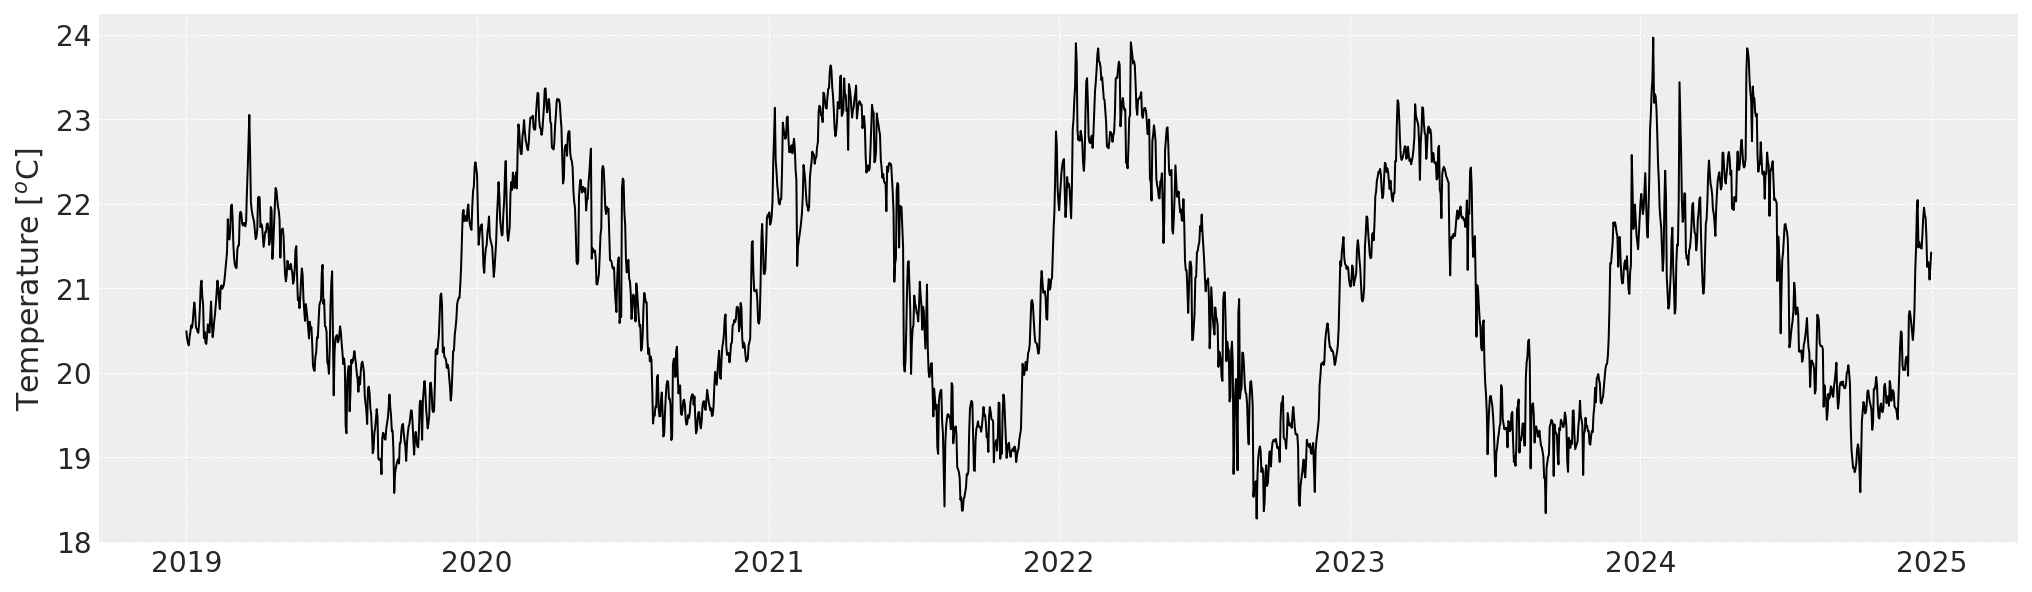

In [4]:
# ------------------------------------------------------------------------------
# 1. Load Timeseries, for this example here: Extract Copernicus SST (°C) for 2019–2025
# ------------------------------------------------------------------------------
ds_raw_C = (
    ds_raw
    .sel(time=slice(pd.to_datetime("2019-01-01"), pd.to_datetime("2025-01-01")))
    .analysed_sst
    .mean("latitude")    # average spatially over latitude
    .mean("longitude")   # average spatially over longitude
    - 273.15             # convert from Kelvin to Celsius
)

print(f"Length ds_raw_C: {len(ds_raw_C) / 365.25:.2f} yrs")

# ------------------------------------------------------------------------------
# 2. Extract time and temperature arrays
# ------------------------------------------------------------------------------

time_array_cop = ds_raw_C.time
temp_array_cop = ds_raw_C.values

print(f"Mean temperature: {np.floor(np.nanmean(temp_array_cop)):.0f} °C")

# ------------------------------------------------------------------------------
# 3. Plot raw SST time series
# ------------------------------------------------------------------------------

plt.plot(time_array_cop, temp_array_cop, color="black", lw=1)
plt.ylabel("Temperature [$^{o}$C]")

# ------------------------------------------------------------------------------
# 4. Save figure
# ------------------------------------------------------------------------------

plt.savefig(f"{figures_folder}/timeseries_raw.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{figures_folder}/timeseries_raw.pdf", dpi=300, bbox_inches="tight")


## Create weekly data for uncertainty analysis

W-SUN
Start date: 2019-01-06 00:00:00
End date: 2025-01-05 00:00:00


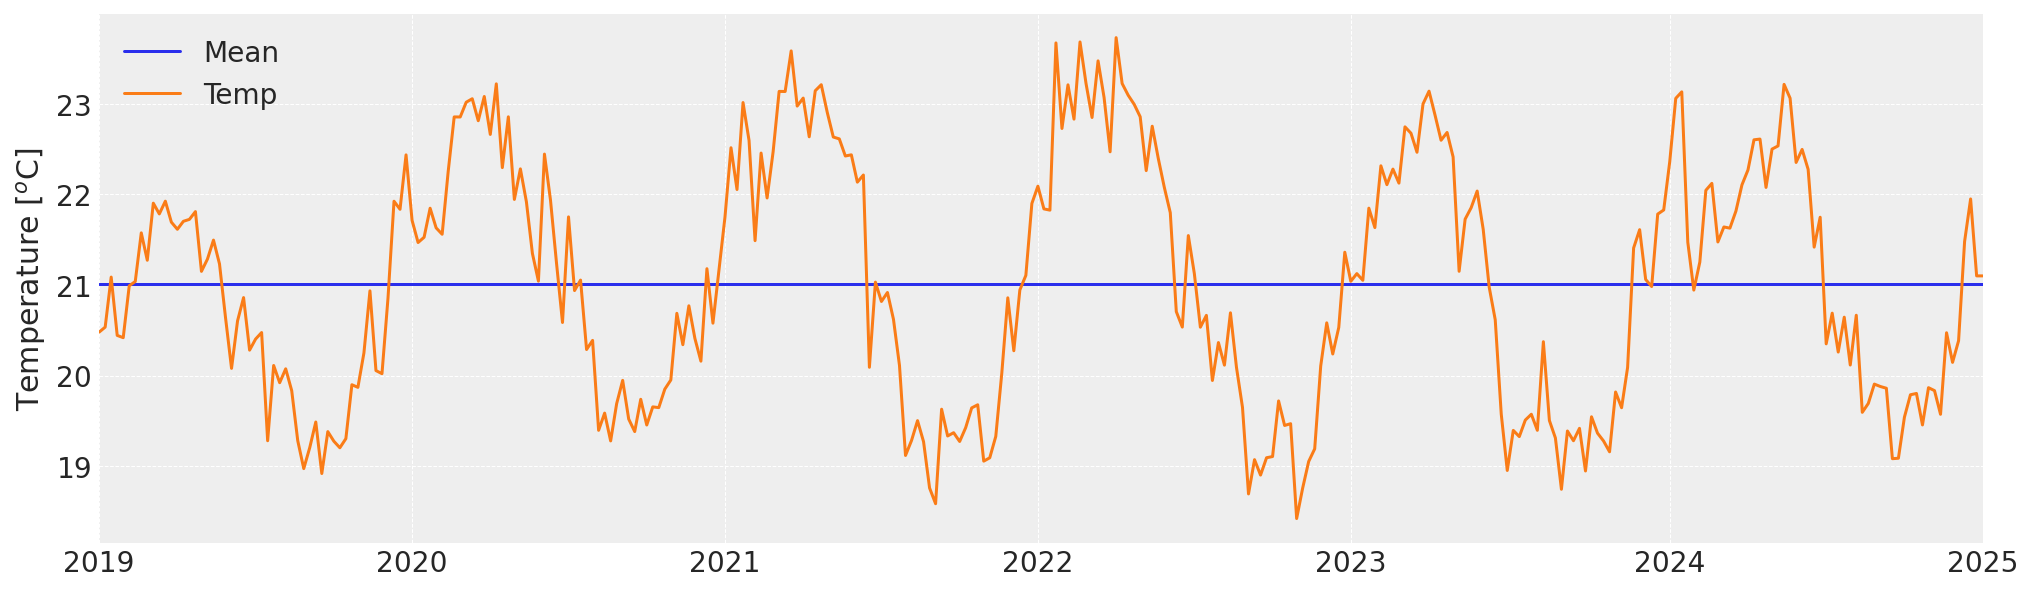

In [5]:
# ------------------------------------------------------------------------------
# 1. Build daily temperature DataFrame
# ------------------------------------------------------------------------------
df_C = pd.DataFrame({
    "Mean": np.zeros(len(temp_array_cop)) + np.nanmean(temp_array_cop),  # global mean
    "Temp": temp_array_cop                                               # daily temps
}, index=time_array_cop)

# ------------------------------------------------------------------------------
# 2. Convert to weekly time series
# ------------------------------------------------------------------------------
# Resample to weekly frequency with linear interpolation
df_w = df_C.resample("W").interpolate("linear").copy()

# ------------------------------------------------------------------------------
# 3. Plot weekly time series
# ------------------------------------------------------------------------------
df_w.plot()
plt.ylabel("Temperature [$^{o}$C]")

# Save weekly series to CSV
df_w.to_csv(f"{figures_folder}/Weekly_timeseries.csv")

# ------------------------------------------------------------------------------
# 4. Get seasonal length & frequency metadata
# ------------------------------------------------------------------------------
seas_length, freq = get_freq_seaslenght(df_w.index)
print(freq)
print(f"Start date: {df_w.index[0]}")
print(f"End date: {df_w.index[-1]}")

# ------------------------------------------------------------------------------
# 5. Save plots
# ------------------------------------------------------------------------------
plt.savefig(f"{figures_folder}/timeseries_{freq}.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{figures_folder}/timeseries_{freq}.pdf", dpi=300, bbox_inches="tight")

## Hobday 30yrs Climatology and Threshold

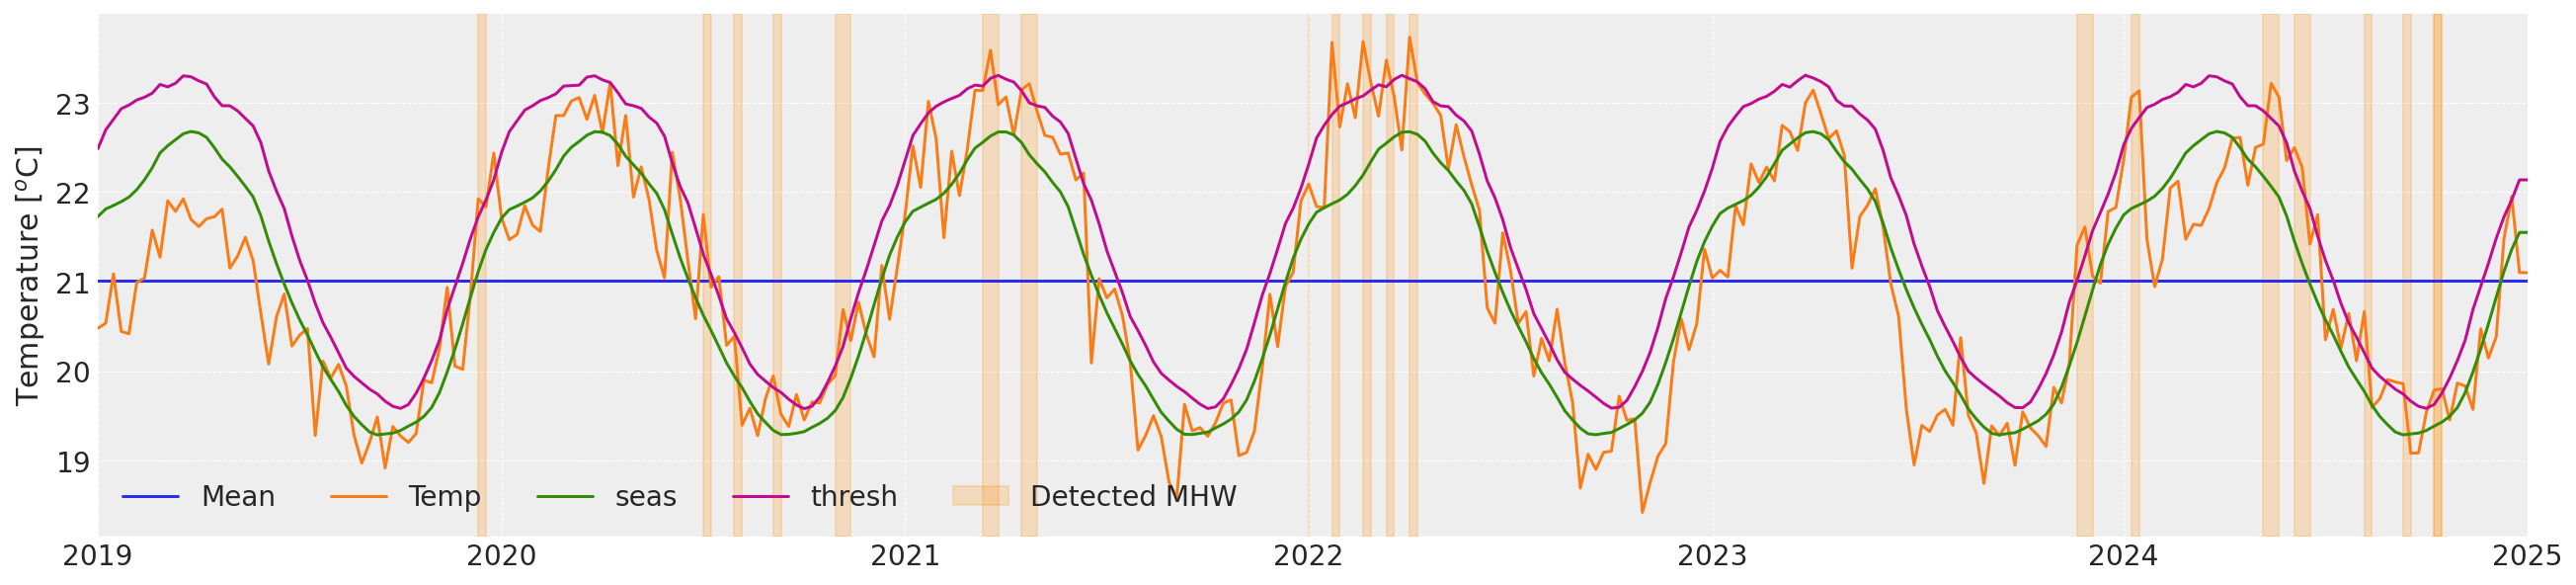

In [6]:
# ------------------------------------------------------------------------------
# 1. Calculate Hobday climatology & threshold 
# ------------------------------------------------------------------------------

# Apply 7-day rolling mean to daily temperatures
df_C_roll = df_C.rolling(7, min_periods=1, center=True).mean().copy()

# Compute marine heatwaves (MHWs), climatology, and threshold
mhws_, clim_, times_dates_mhw_ = comparing_to_Hobday(df_C_roll.Temp)

# Save detected MHW dictionary
np.save(f"{figures_folder}/mhw_dict.npy", mhws_)

# Save daily climatology & threshold to CSV
mhw_df = pd.DataFrame({
    "seas": clim_["seas"],
    "thresh": clim_["thresh"]
}, index=pd.to_datetime(times_dates_mhw_))
mhw_df.to_csv(f"{figures_folder}/Daily_Hobday.csv")

# ------------------------------------------------------------------------------
# 2. Add weekly climatology & threshold to weekly dataset
# ------------------------------------------------------------------------------

df_w["seas"] = mhw_df["seas"].resample(freq).interpolate("linear")
df_w["thresh"] = mhw_df["thresh"].resample(freq).interpolate("linear")

# ------------------------------------------------------------------------------
# 3. Plot time series with detected MHWs
# ------------------------------------------------------------------------------

fig, ax = plt.subplots(1, 1, figsize=(18, 4))

# Plot weekly time series with climatology & threshold
df_w.plot(ax=ax)

# Shade detected MHW periods
for ds_start, ds_end in zip(mhws_["date_start"], mhws_["date_end"]):
    ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color="darkorange", alpha=0.2)
# Add legend label on last shaded event
ax.axvspan(
    pd.Timestamp(ds_start), pd.Timestamp(ds_end),
    color="darkorange", alpha=0.2, label="Detected MHW"
)

# Axis labels & legend
ax.set_ylabel("Temperature [$^{o}$C]")
ax.legend(ncols=5)

# Save high-resolution plots
plt.savefig(f"{figures_folder}/timeseries_with_climThresh_{freq}.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{figures_folder}/timeseries_with_climThresh_{freq}.pdf", dpi=300, bbox_inches="tight")

# ------------------------------------------------------------------------------
# 4. Save weekly dataset with climatology & threshold
# ------------------------------------------------------------------------------

df_w.to_csv(f"{figures_folder}/Weekly_timeseries_withClimThresh.csv")


## Based on Climatology and Threshold suggest right Harmonics Order

Seasonal length: 52


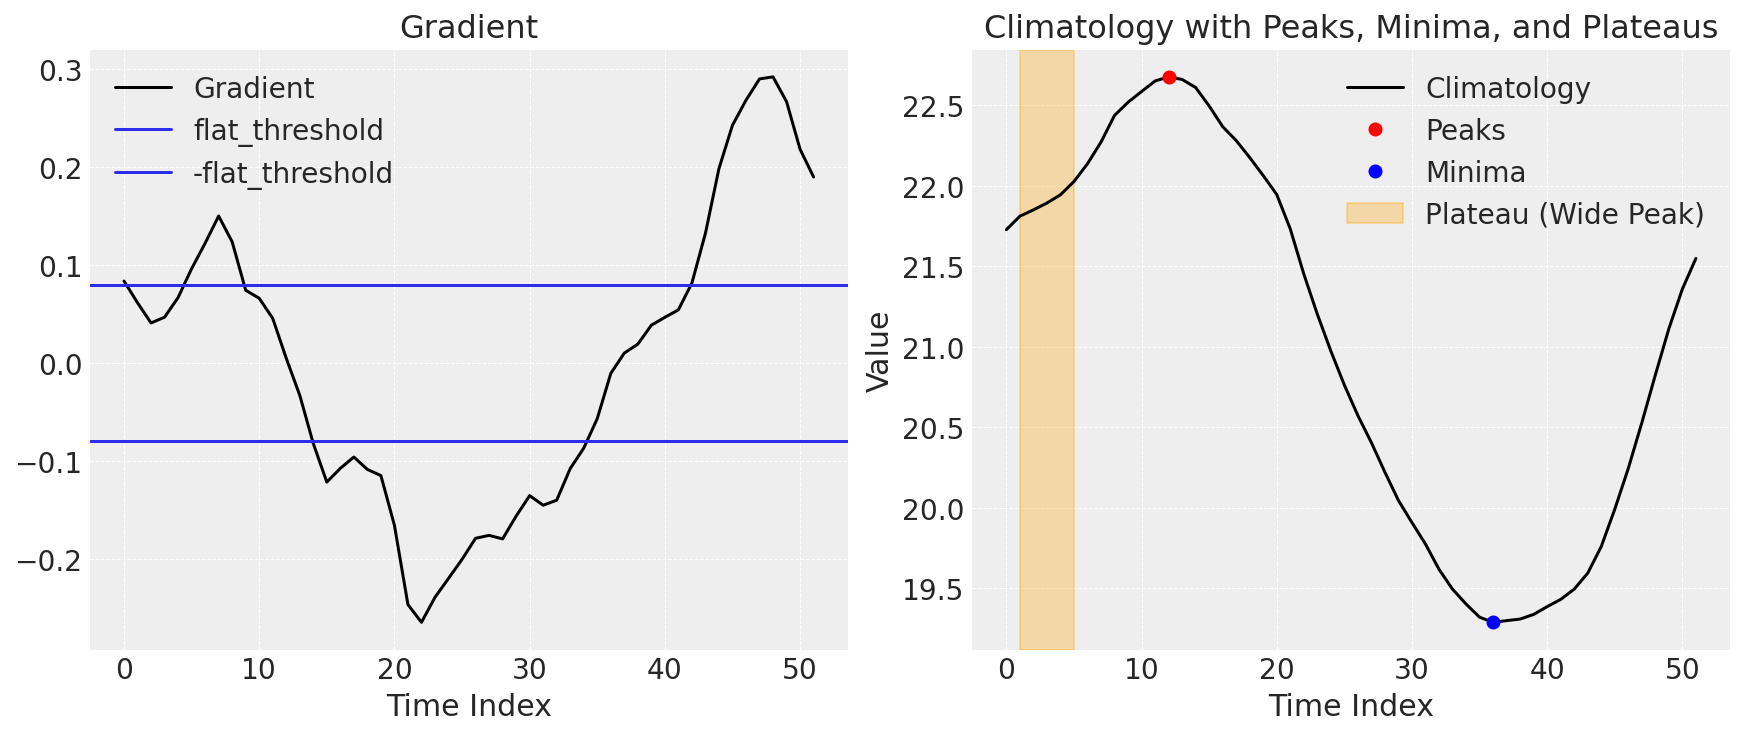

Final suggested harmonics n_order: 1 to 3


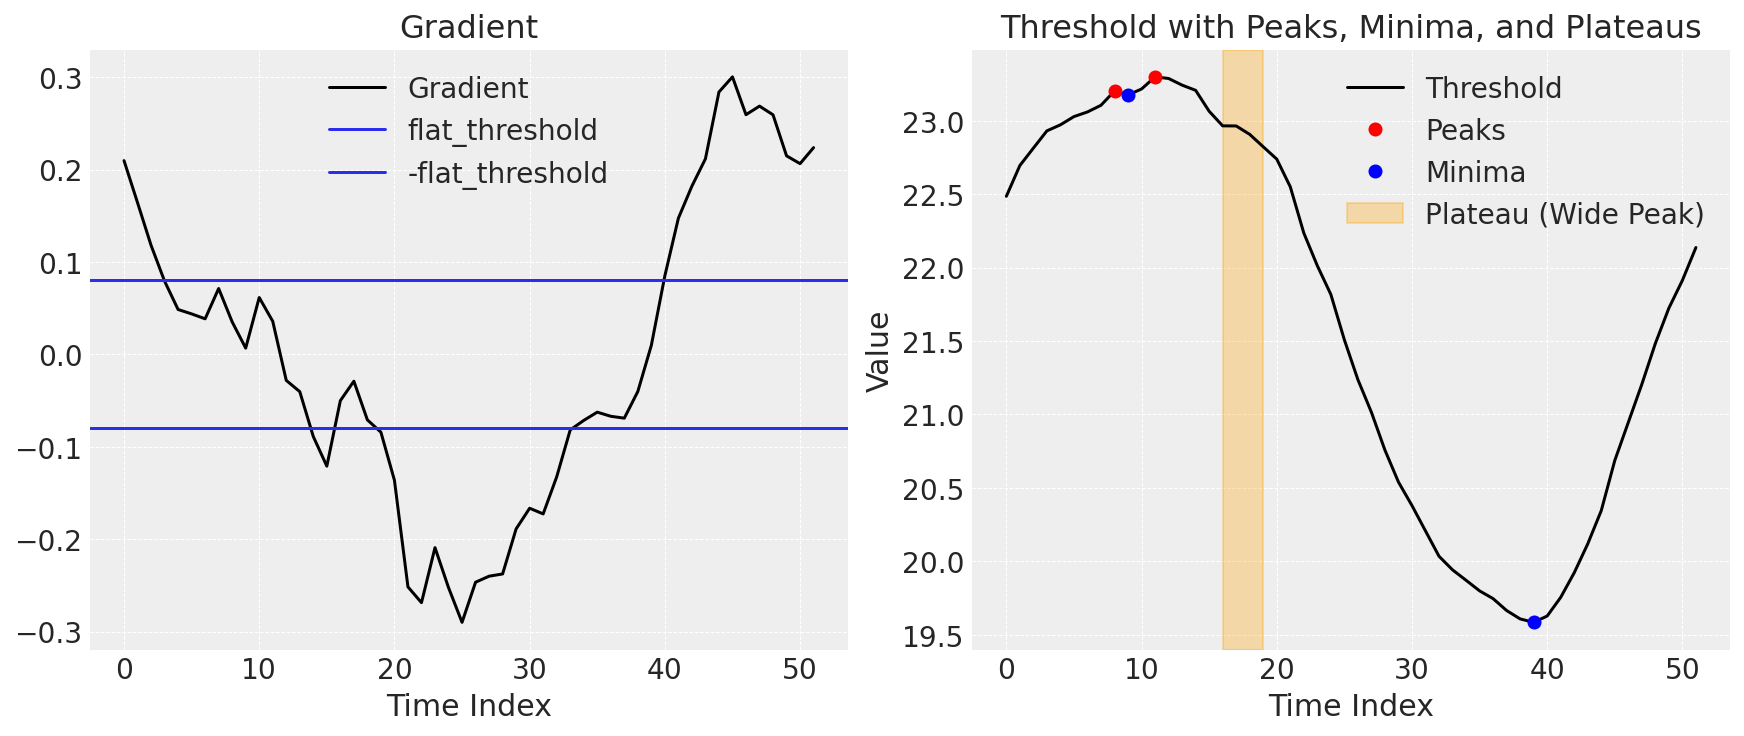

Final suggested harmonics n_order: 2 to 4


In [7]:
seas_length, freq = get_freq_seaslenght(df_w.index)
print("Seasonal length:", seas_length)
final_n_order = detect_peaks_minima_plateaus(df_w['seas'][:int(seas_length)], var = 'Climatology')
final_n_order2 = detect_peaks_minima_plateaus(df_w['thresh'][:int(seas_length)], var = 'Threshold')

# Model Setup

## PyMC Model function

In [8]:
def pymc_function(eps_data, n_order = 1, mean_temp = 15):

    ## check timestep and frequency from dataframe 
    seas_length, freq = get_freq_seaslenght(eps_data.index)
   
    #### generating fourier features:
    t_data = list(range(len(eps_data)))
    
    periods = np.array(t_data) / seas_length
    ff = pd.DataFrame( { f"{func}_order_{order}": getattr(np, func)(2 * np.pi * periods * order)
            for order in range(1, n_order + 1) for func in ("sin", "cos")})
    ff = ff.to_numpy().T

    ### define model
    with pm.Model() as EPS:
        pass

    ### Add coordinates to model   
    EPS.add_coord("obs_id", t_data)
    EPS.add_coord("fourier_features", np.arange(len(ff)))

    with EPS:
        ## Data containers to enable prediction
        # t = pm.Data ("t", t_data, dims="obs_id")
        y = pm.Data ("y", eps_data.astype(float), dims="obs_id")
        fourier_terms = pm.Data ("fourier_terms", ff)
        
        #### --- a and sigma
        alpha = pm.Normal('alpha', mu=mean_temp, sigma=2 )
        sigma = pm.TruncatedNormal('sigma', mu=1.5, sigma=0.5 , lower=0)


        #### --- seasonality
        beta_fourier = pm.Normal(name="beta_fourier", mu=0, sigma=2, dims="fourier_features")
        seasonality = pm.Deterministic("seasonality", pm.math.dot(beta_fourier, fourier_terms), dims="obs_id")
    
        #### --- mu 
        mu = pm.Deterministic("mu",  alpha + seasonality, dims="obs_id")

        #### --- The Likelihood
        outcome = pm.Normal("likelihood", mu=mu, sigma=sigma, observed=y, dims="obs_id")

        #### --- Sampling
        idata_eps = pm.sample_prior_predictive()
        idata_eps.extend(pm.sample(**sampler_kwargs()))
        idata_eps.extend(pm.sample_posterior_predictive(idata_eps))
    
        
    return idata_eps, EPS

# Daily Model Run

##  Running Model single time

In [9]:
label_years = '6yrs'
mean_temperature = 20 

print(f"Harmonics order: {final_n_order}")
print(f"Mean Temperature: {mean_temperature}")

Harmonics order: 3
Mean Temperature: 20


In [10]:
idata_eps, model_eps = pymc_function(df_C_roll.Temp, n_order=final_n_order, mean_temp = mean_temperature)

C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\pytensor\link\c\cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Sampling: [alpha, beta_fourier, likelihood, sigma]


Progress,Draws,Divergences,Step Size,Gradients/Draw
,1500,0,0.90,7
,1500,0,0.88,3
,1500,0,0.88,7
,1500,0,0.91,7


Sampling: [likelihood]


C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\rich\live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

## Show Uncertainty plot

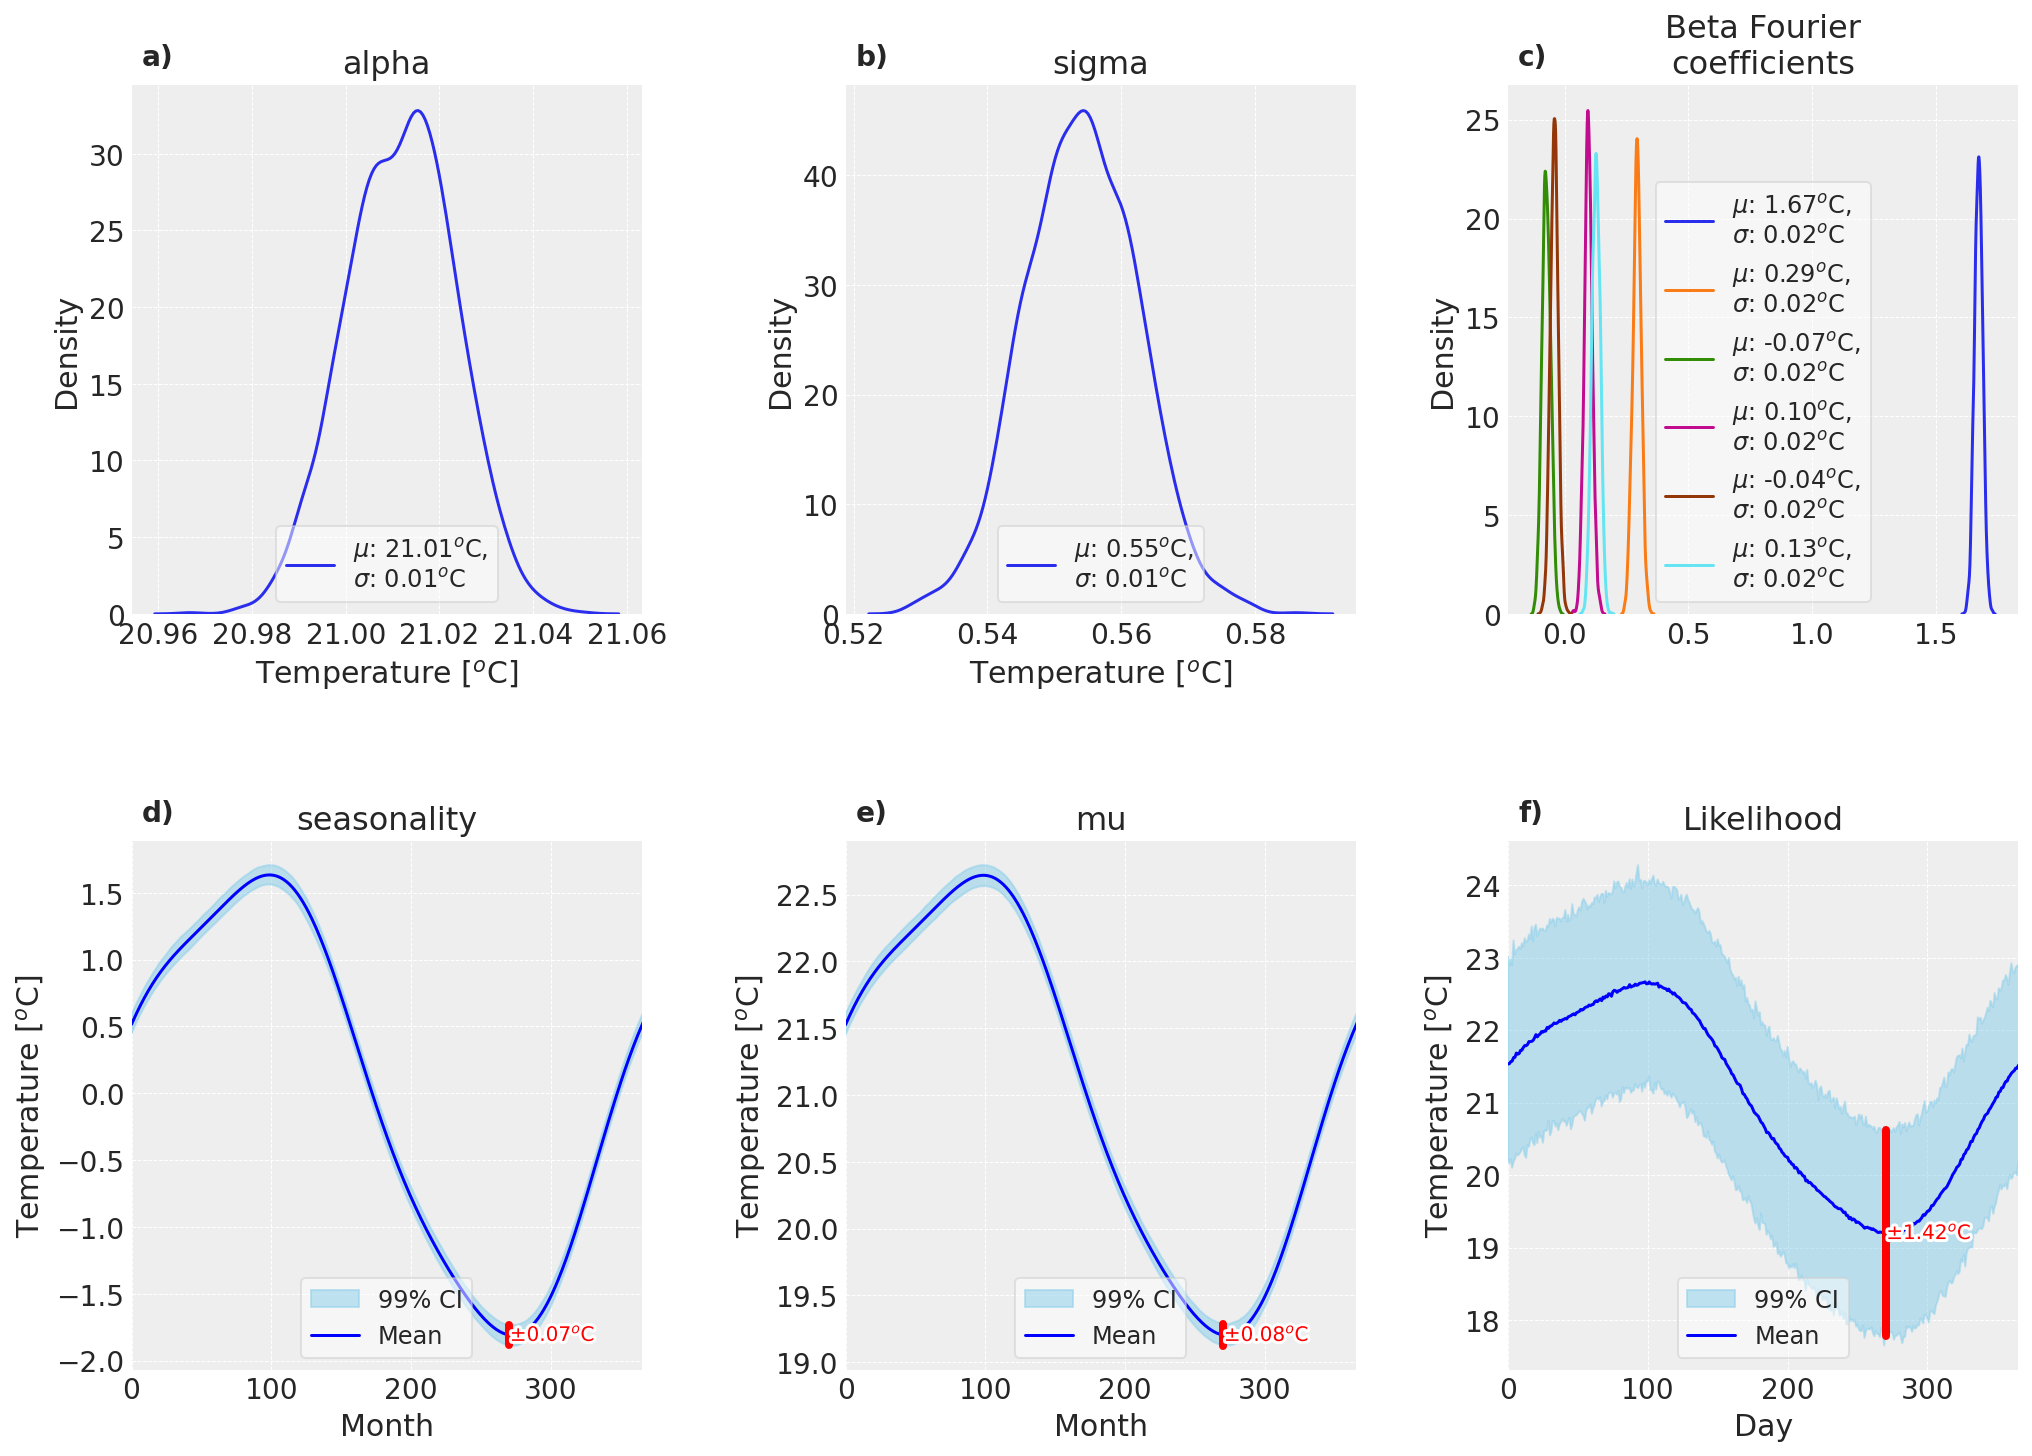

In [12]:
# ------------------------------------------------------------------------------
# Setup
# ------------------------------------------------------------------------------
# Variables to analyze
scalar_vars = ["alpha", "sigma"]  # Single-value parameters
time_vars = ["seasonality", "mu"]            # Time-dependent parameters

# Count of subplots
n_scalar = len(scalar_vars)
n_time = len(time_vars)
total = n_scalar + n_time + 1  # +1 for likelihood plot

# Create figure with subplots (2 rows × 4 columns)
fig, axes = plt.subplots(2, 3, figsize=(14, 10), gridspec_kw={'wspace': 0.1, 'hspace': 0.15})
axes = axes.flatten()

# ------------------------------------------------------------------------------
# 1. Scalar variables – posterior distributions
# ------------------------------------------------------------------------------
for i, var in enumerate(scalar_vars):
    ax = axes[i]

    # Flatten MCMC chains and draws
    values = idata_eps.posterior[var].stack(sample=("chain", "draw")).values

    # Fit normal distribution to posterior samples
    mu, std = norm.fit(values)

    # Kernel density estimate (KDE) of posterior distribution
    sns.kdeplot(values, label=f"$\mu$: {mu:.2f}$^{{o}}$C,\n$\sigma$: {std:.2f}$^{{o}}$C",  linestyle="-", ax=ax )

    ax.set_title(f"{var}")
    ax.set_xlabel('Temperature [$^{o}$C]')
    ax.legend( fontsize=12, frameon=True, framealpha=0.5, facecolor='white', loc='lower center')

# ------------------------------------------------------------------------------
# 1b. Fourier coefficients (example of multiple scalar parameters)
# ------------------------------------------------------------------------------
ax = axes[2]  # Place in subplot (adjust if needed)
values = idata_eps.posterior['beta_fourier'].stack(sample=("chain", "draw")).values
n_coeff = values.shape[0]

# Plot distribution for each Fourier coefficient
for i in range(n_coeff):
    coef_values = values[i, :]
    mu, std = norm.fit(coef_values)
    sns.kdeplot( coef_values,label=f"$\mu$: {mu:.2f}$^{{o}}$C,\n$\sigma$: {std:.2f}$^{{o}}$C",linestyle="-", ax=ax )

ax.set_title("Beta Fourier\ncoefficients")
ax.legend( fontsize=12, frameon=True, framealpha=0.5,facecolor='white', loc='lower center')

# ------------------------------------------------------------------------------
# 2. Time-dependent variables – mean ± 99% CI
# ------------------------------------------------------------------------------
for j, var in enumerate(time_vars):
    ax = axes[n_scalar + j + 1]

    # Extract values (obs × samples)
    values = idata_eps.posterior[var].stack(sample=("chain", "draw")).values
    mean = values.mean(axis=1)
    lower = np.percentile(values, 0.5, axis=1)
    upper = np.percentile(values, 99.5, axis=1)

    # Plot mean and uncertainty band
    ax.fill_between(range(len(mean)), lower, upper, color='skyblue', alpha=0.5, label='99% CI')
    ax.plot(mean, color='blue', label='Mean')

    # Reference bar showing average uncertainty magnitude
    ci_width = np.mean(upper - lower) / 2
    x_pos = 270
    y_pos = mean[x_pos]
    ax.plot([x_pos, x_pos], [y_pos - ci_width, y_pos + ci_width], color='red', lw=4)
    txt = ax.text(x_pos + 0.5, y_pos, f"±{ci_width:.2f}$^{{o}}$C", color='red', va='center')
    txt.set_path_effects([PathEffects.withStroke(linewidth=3, foreground="white")])

    ax.set_xlabel("Month")
    ax.set_title(var)
    ax.set_ylabel('Temperature [$^{o}$C]')
    ax.set_xlim(0, 365)
    ax.legend( fontsize=12, frameon=True, framealpha=0.5,facecolor='white', loc='lower center')

# ------------------------------------------------------------------------------
# 3. Likelihood / Posterior predictive distribution
# ------------------------------------------------------------------------------
ax = axes[n_scalar + j + 2]

values = idata_eps.posterior_predictive['likelihood'].stack(sample=("chain", "draw")).values
mean = values.mean(axis=1)
lower = np.percentile(values, 0.5, axis=1)
upper = np.percentile(values, 99.5, axis=1)

# Plot mean and uncertainty band
ax.fill_between(range(len(mean)), lower, upper, color='skyblue', alpha=0.5, label='99% CI')
ax.plot(mean, color='blue', label='Mean')

# Add reference bar for uncertainty
ci_width = np.mean(upper - lower) / 2
x_pos = 270
y_pos = mean[x_pos]
ax.plot([x_pos, x_pos], [y_pos - ci_width, y_pos + ci_width], color='red', lw=4)
txt = ax.text(x_pos + 0.5, y_pos, f"±{ci_width:.2f}$^{{o}}$C", color='red', va='center')
txt.set_path_effects([PathEffects.withStroke(linewidth=3, foreground="white")])

ax.set_xlabel("Day")
ax.set_title("Likelihood")
ax.set_ylabel('Temperature [$^{o}$C]')
ax.set_xlim(0, 365)
ax.legend(fontsize=12, frameon=True, framealpha=0.5,facecolor='white', loc='lower center')

# ------------------------------------------------------------------------------
# 4. Formatting: subplot labels & cleanup
# ------------------------------------------------------------------------------
# Add panel labels (a, b, c, …)
labels = [f"{ch})" for ch in string.ascii_lowercase[:len(axes.flat)]]
for ax, lab in zip(axes.flat, labels):
    ax.text( 0.02, 1.08, lab, transform=ax.transAxes,fontsize=14, fontweight='bold', va='top',
            ha='left',bbox=dict(facecolor='white', alpha=0.0, edgecolor='none', pad=0))

# Remove unused subplot (last one in 2x4 grid)
# fig.delaxes(axes[7])

# ------------------------------------------------------------------------------
# Save & show
# ------------------------------------------------------------------------------
plt.savefig(os.path.join(figures_folder, "UncertaintyExampleParameters.png"), dpi=300)
plt.savefig(os.path.join(figures_folder, "UncertaintyExampleParameters.pdf"), dpi=300)
plt.show()


C:\Users\24048369\AppData\Local\Temp\ipykernel_31568\3896723381.py:77: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


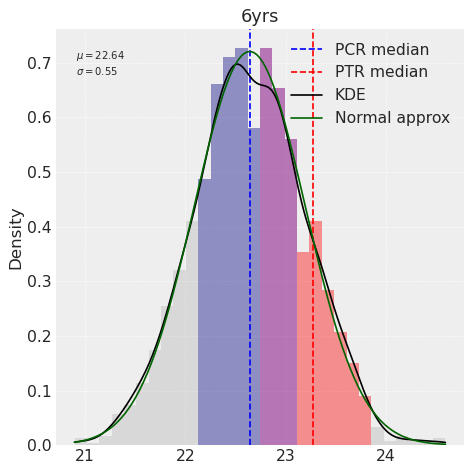

In [13]:
# ------------------------------------------------------------------------------
# Setup
# ------------------------------------------------------------------------------
# Choose a specific day to highlight (index in time_array)
day_idx = 100  # <-- adjust as needed

# Create figure
fig, ax0 = plt.subplots(1, 1, figsize=(6, 6), dpi=80, sharey=True, sharex=True)

# ------------------------------------------------------------------------------
# Extract samples & derived metrics
# ------------------------------------------------------------------------------
# Posterior predictive likelihood samples for the chosen day
likelihood_samples = (
    idata_eps.posterior_predictive["likelihood"]
    .stack(sample=("chain", "draw"))
    .values[day_idx, :]
)

# Extract PCR & PTR values (quantile-based uncertainty bands)
PCR, PTR, time_array = get_PCRs_and_PTR(idata_eps, df_C_roll)
pcr_val = PCR[:, day_idx]
ptr_val = PTR[:, day_idx]

# ------------------------------------------------------------------------------
# Histogram with colored credible intervals
# ------------------------------------------------------------------------------
# Compute 99% credible intervals (0.5–99.5th percentiles)
pcr_low, pcr_high = np.percentile(pcr_val, [0.5, 99.5])
ptr_low, ptr_high = np.percentile(ptr_val, [0.5, 99.5])

# Plot base histogram of likelihood samples
counts, bins, patches = ax0.hist(likelihood_samples, bins=30, density=True, alpha=0.2, color="gray")

# Color histogram bars depending on PCR/PTR overlap
for patch, left, right in zip(patches, bins[:-1], bins[1:]):
    in_pcr = (right >= pcr_low) and (left <= pcr_high)
    in_ptr = (right >= ptr_low) and (left <= ptr_high)

    if in_pcr and in_ptr:
        patch.set_facecolor("purple")   # Overlapping PCR & PTR
        patch.set_alpha(0.5)
    elif in_pcr:
        patch.set_facecolor("navy")     # PCR only
        patch.set_alpha(0.4)
    elif in_ptr:
        patch.set_facecolor("red")      # PTR only
        patch.set_alpha(0.4)

# ------------------------------------------------------------------------------
# Overlay reference distributions
# ------------------------------------------------------------------------------
# Median reference lines
ax0.axvline(np.median(pcr_val), color="blue", linestyle="--", label="PCR median")
ax0.axvline(np.median(ptr_val), color="red", linestyle="--", label="PTR median")

# KDE of likelihood samples
kde = gaussian_kde(likelihood_samples)
x_vals = np.linspace(likelihood_samples.min(), likelihood_samples.max(), 200)
ax0.plot(x_vals, kde(x_vals), color="black", lw=1.5, label="KDE")

# Normal approximation for comparison
mu = np.mean(likelihood_samples)
sigma = np.std(likelihood_samples)
ax0.plot(x_vals, norm.pdf(x_vals, mu, sigma), color="darkgreen", lw=1.5, label="Normal approx")

# Annotate mean & std
ax0.text( 0.05, 0.95, f"$\mu={mu:.2f}$\n$\sigma={sigma:.2f}$", transform=ax0.transAxes, fontsize=9, va="top")

# ------------------------------------------------------------------------------
# Formatting
# ------------------------------------------------------------------------------
ax0.set_title(label_years)
ax0.set_ylabel("Density")
ax0.legend()

plt.tight_layout()
plt.show()

## Saving Model Output

In [14]:
# ## if you wanna save the output 
idata_eps.to_netcdf( f'{figures_folder}/Idata_eps_{label_years}.nc')
df_C_roll.to_pickle(f'{figures_folder}/df_C_roll_{label_years}.pkl')


## Plot short PTR,PCR and HPS


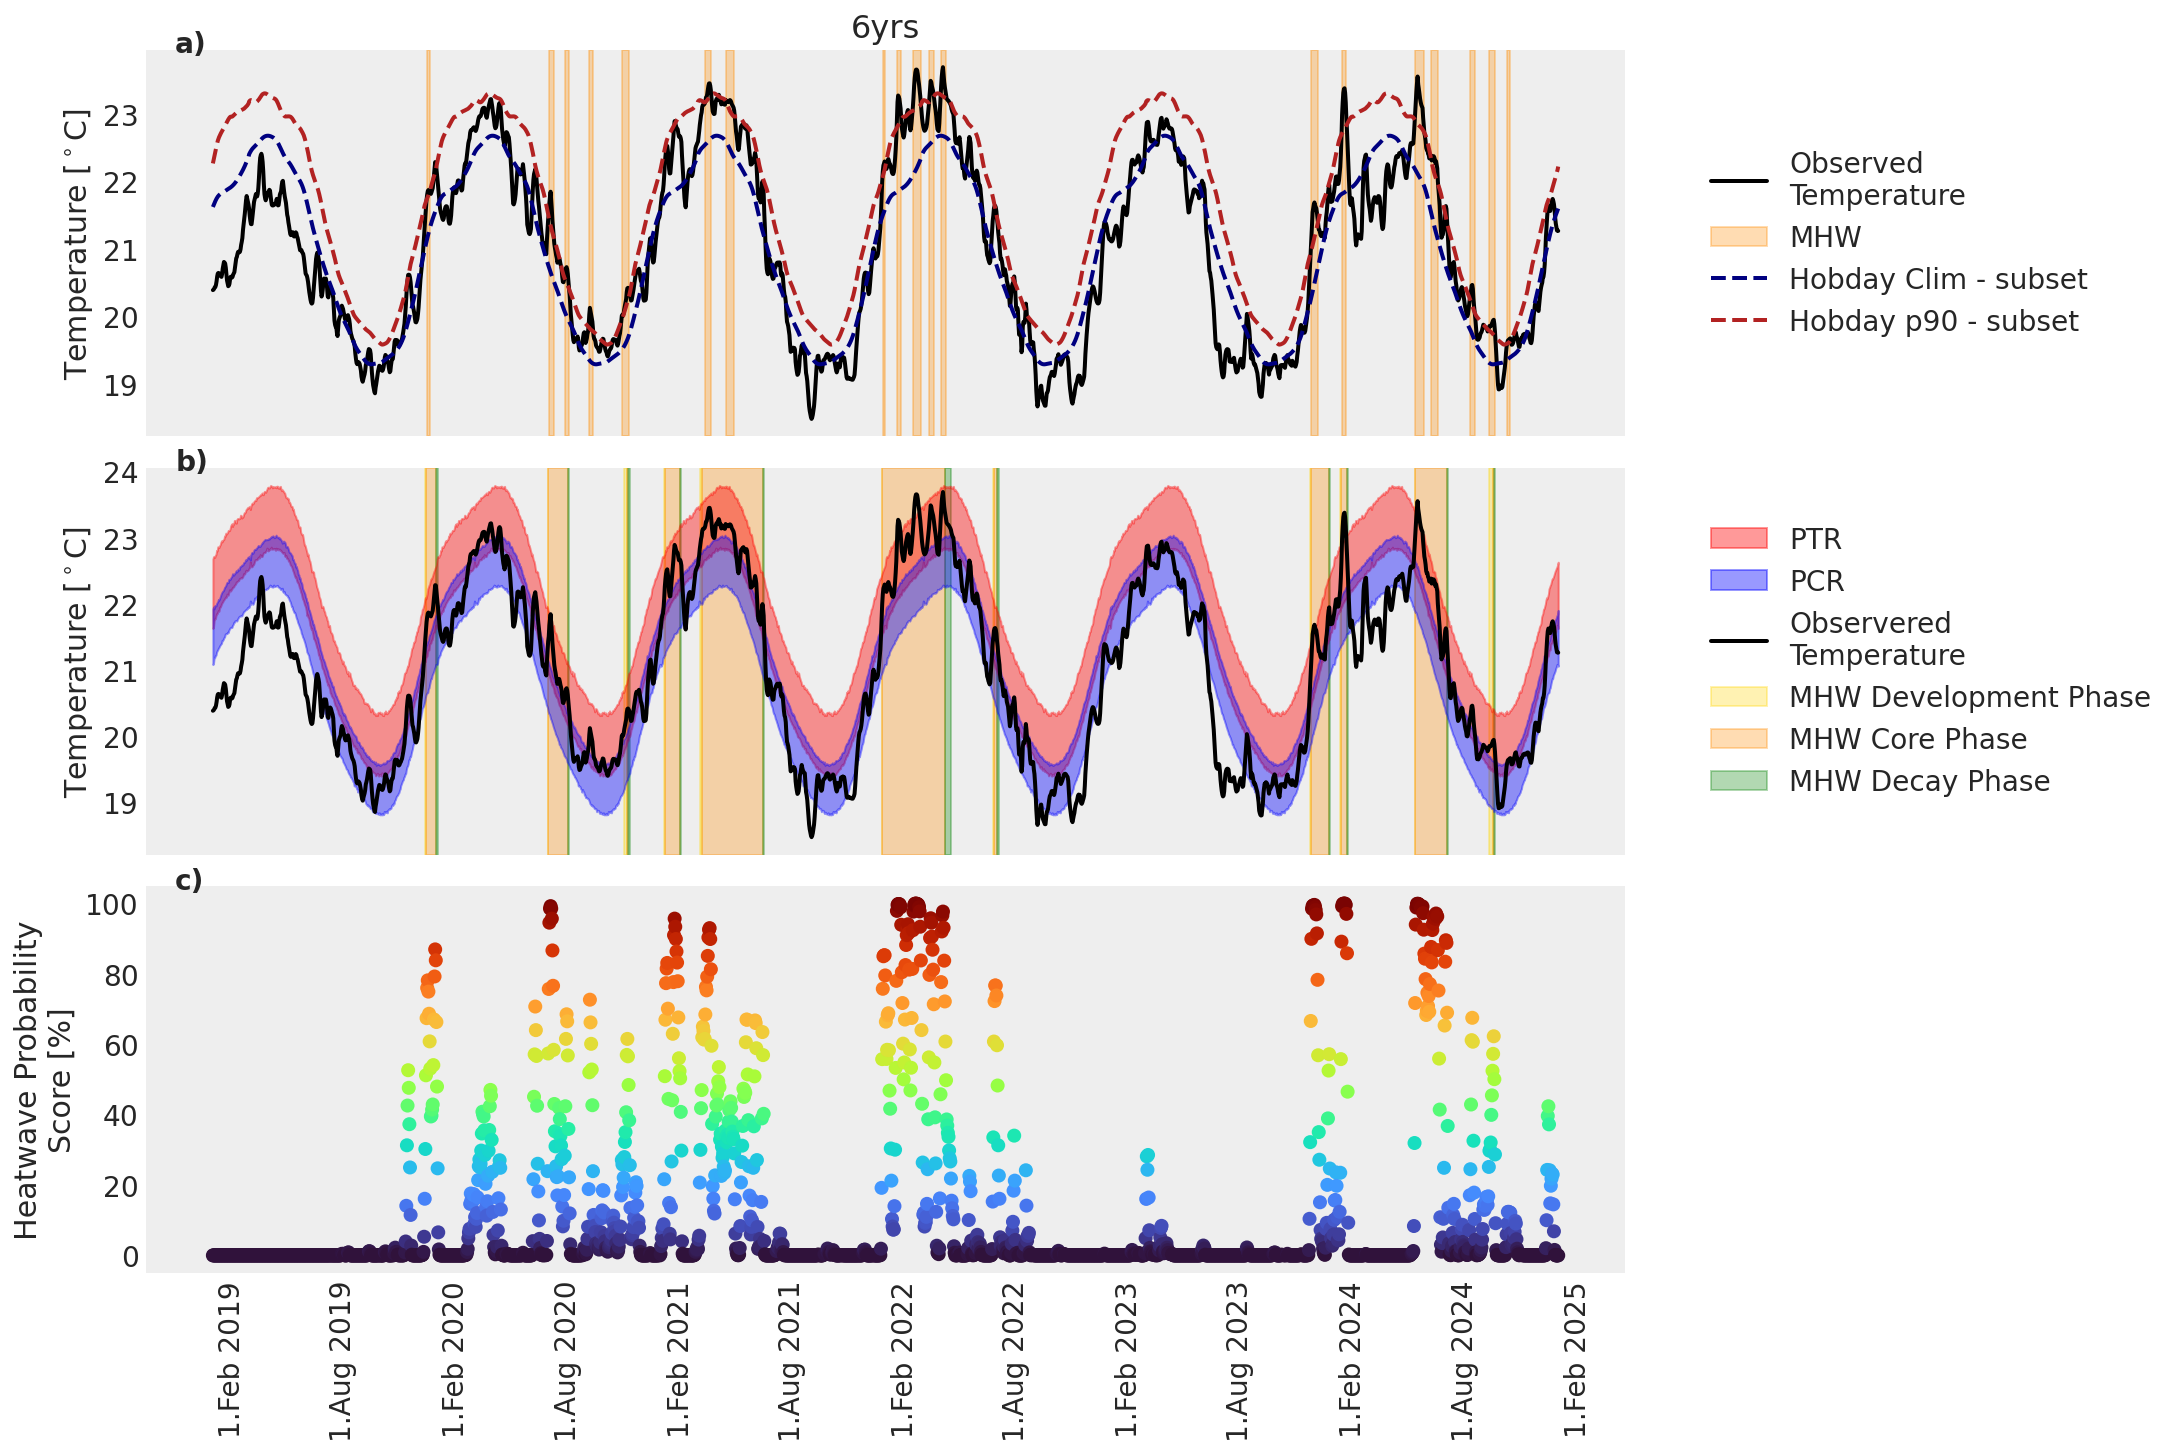

In [15]:
# ------------------------------------------------------------------------------
# Setup
# ------------------------------------------------------------------------------

fig, axs = plt.subplots( ncols=1, nrows=3, figsize=(15, 10),sharey="row", sharex=True)
axs = axs.flatten()

# Set y-axis labels for each subplot
axs[0].set_ylabel("Temperature [$^\\circ$C]")
axs[1].set_ylabel("Temperature [$^\\circ$C]")
axs[2].set_ylabel("Heatwave Probability\nScore [%]")

# ------------------------------------------------------------------------------
# Calculate metrics: PCR, PTR, HPS
# ------------------------------------------------------------------------------

# Posterior Climate Reference (PCR), Posterior Threshold Reference (PTR), time axis
PCR, PTR, time_array = get_PCRs_and_PTR(idata_eps, df_C_roll)

# Heatwave Probability Score (PTR exceedance probability)
prob_PTR = calculate_prob_PTR(df_C_roll, PTR, variable="Temp")

# ------------------------------------------------------------------------------
# 1. Observed temperature vs Hobday climatology & thresholds
# ------------------------------------------------------------------------------

ax = axs[0]
ax.set_title(label_years)

# Plot observed rolling mean temperature
ax.plot( df_C_roll.index, df_C_roll.Temp,label="Observed\nTemperature", color="black", lw=2)

# Shade detected marine heatwaves
for ds_start, ds_end in zip(mhws_["date_start"][:-1], mhws_["date_end"][:-1]):
    ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color="darkorange", alpha=0.3)
# Last event (with legend label)
ax.axvspan( pd.Timestamp(mhws_["date_start"][-1]), pd.Timestamp(mhws_["date_end"][-1]),color="darkorange", alpha=0.3, label="MHW")

# Hobday climatology & threshold (subset)
ax.plot(df_C_roll.index, clim_["seas"], color="navy", lw=2, ls="--", label="Hobday Clim - subset")
ax.plot(df_C_roll.index, clim_["thresh"], color="firebrick", lw=2, ls="--", label="Hobday p90 - subset")

# ------------------------------------------------------------------------------
# 2. PCR & PTR posterior ranges with detected MHW phases
# ------------------------------------------------------------------------------

ax = axs[1]

# Plot posterior ranges for PCR & PTR
plot_probs_range(PTR, time_array, ax, color="red", label="PTR", mean_line=False)
plot_probs_range(PCR, time_array, ax, color="blue", label="PCR", mean_line=False)

# Detect MHWs based on HPS (heatwave probability score)
mhw_dict_hps = detect_mhws_from_hps(HPS=np.array(prob_PTR), T_obs=df_C_roll.Temp, PCR=PCR, PTR=PTR, time=df_C_roll.index,  
                                    detection_threshold=50, ramp_threshold=20, max_dip=10, min_duration=10)

# Overlay detected MHW phases
plot_mhw_phases( df_C_roll.Temp, np.array(prob_PTR), mhw_dict_hps, ax,detection_threshold=50, ramp_threshold=20)

# ------------------------------------------------------------------------------
# 3. Heatwave Probability Score (HPS)
# ------------------------------------------------------------------------------
ax = axs[2]
scatter = ax.scatter( time_array, prob_PTR, c=prob_PTR, cmap="turbo")

# ------------------------------------------------------------------------------
# Formatting: x-axis ticks and grids
# ------------------------------------------------------------------------------
# Custom date formatting for x-axis
date_format = mdates.DateFormatter("1.%b %Y")  # On Windows: use '%#d.%b'
month_locator = mdates.MonthLocator(interval=6)

for ax in axs:
    ax.xaxis.set_major_locator(month_locator)
    ax.xaxis.set_major_formatter(date_format)
    ax.tick_params(axis="x", rotation=90)  # Rotate for readability
    ax.grid()

# ------------------------------------------------------------------------------
# Legends (only for subplots with entries)
# ------------------------------------------------------------------------------

ncols, nrows = 1, 3
legend_axes_indices = [(row + 1) * ncols - 1 for row in range(nrows)]  # last in each row

for idx in legend_axes_indices:
    ax = axs[idx]
    handles, labels = ax.get_legend_handles_labels()
    if handles:  # Only add legend if entries exist
        ax.legend(handles, labels, loc="center left", bbox_to_anchor=(1.05, 0.5),   borderaxespad=0,frameon=False)

# ------------------------------------------------------------------------------
# Subplot labels (a), b), c), …)
# ------------------------------------------------------------------------------

labels = [f"{ch})" for ch in string.ascii_lowercase[:len(axs.flat)]]
for ax, lab in zip(axs.flat, labels):
    ax.text(0.02, 1.05, lab,transform=ax.transAxes,fontsize=14, fontweight="bold",va="top",
            ha="left", bbox=dict(facecolor="white", alpha=0.0, edgecolor="none", pad=0) )


## Plot Monthly Histograms

C:\Users\24048369\AppData\Local\Temp\ipykernel_31568\819543026.py:64: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


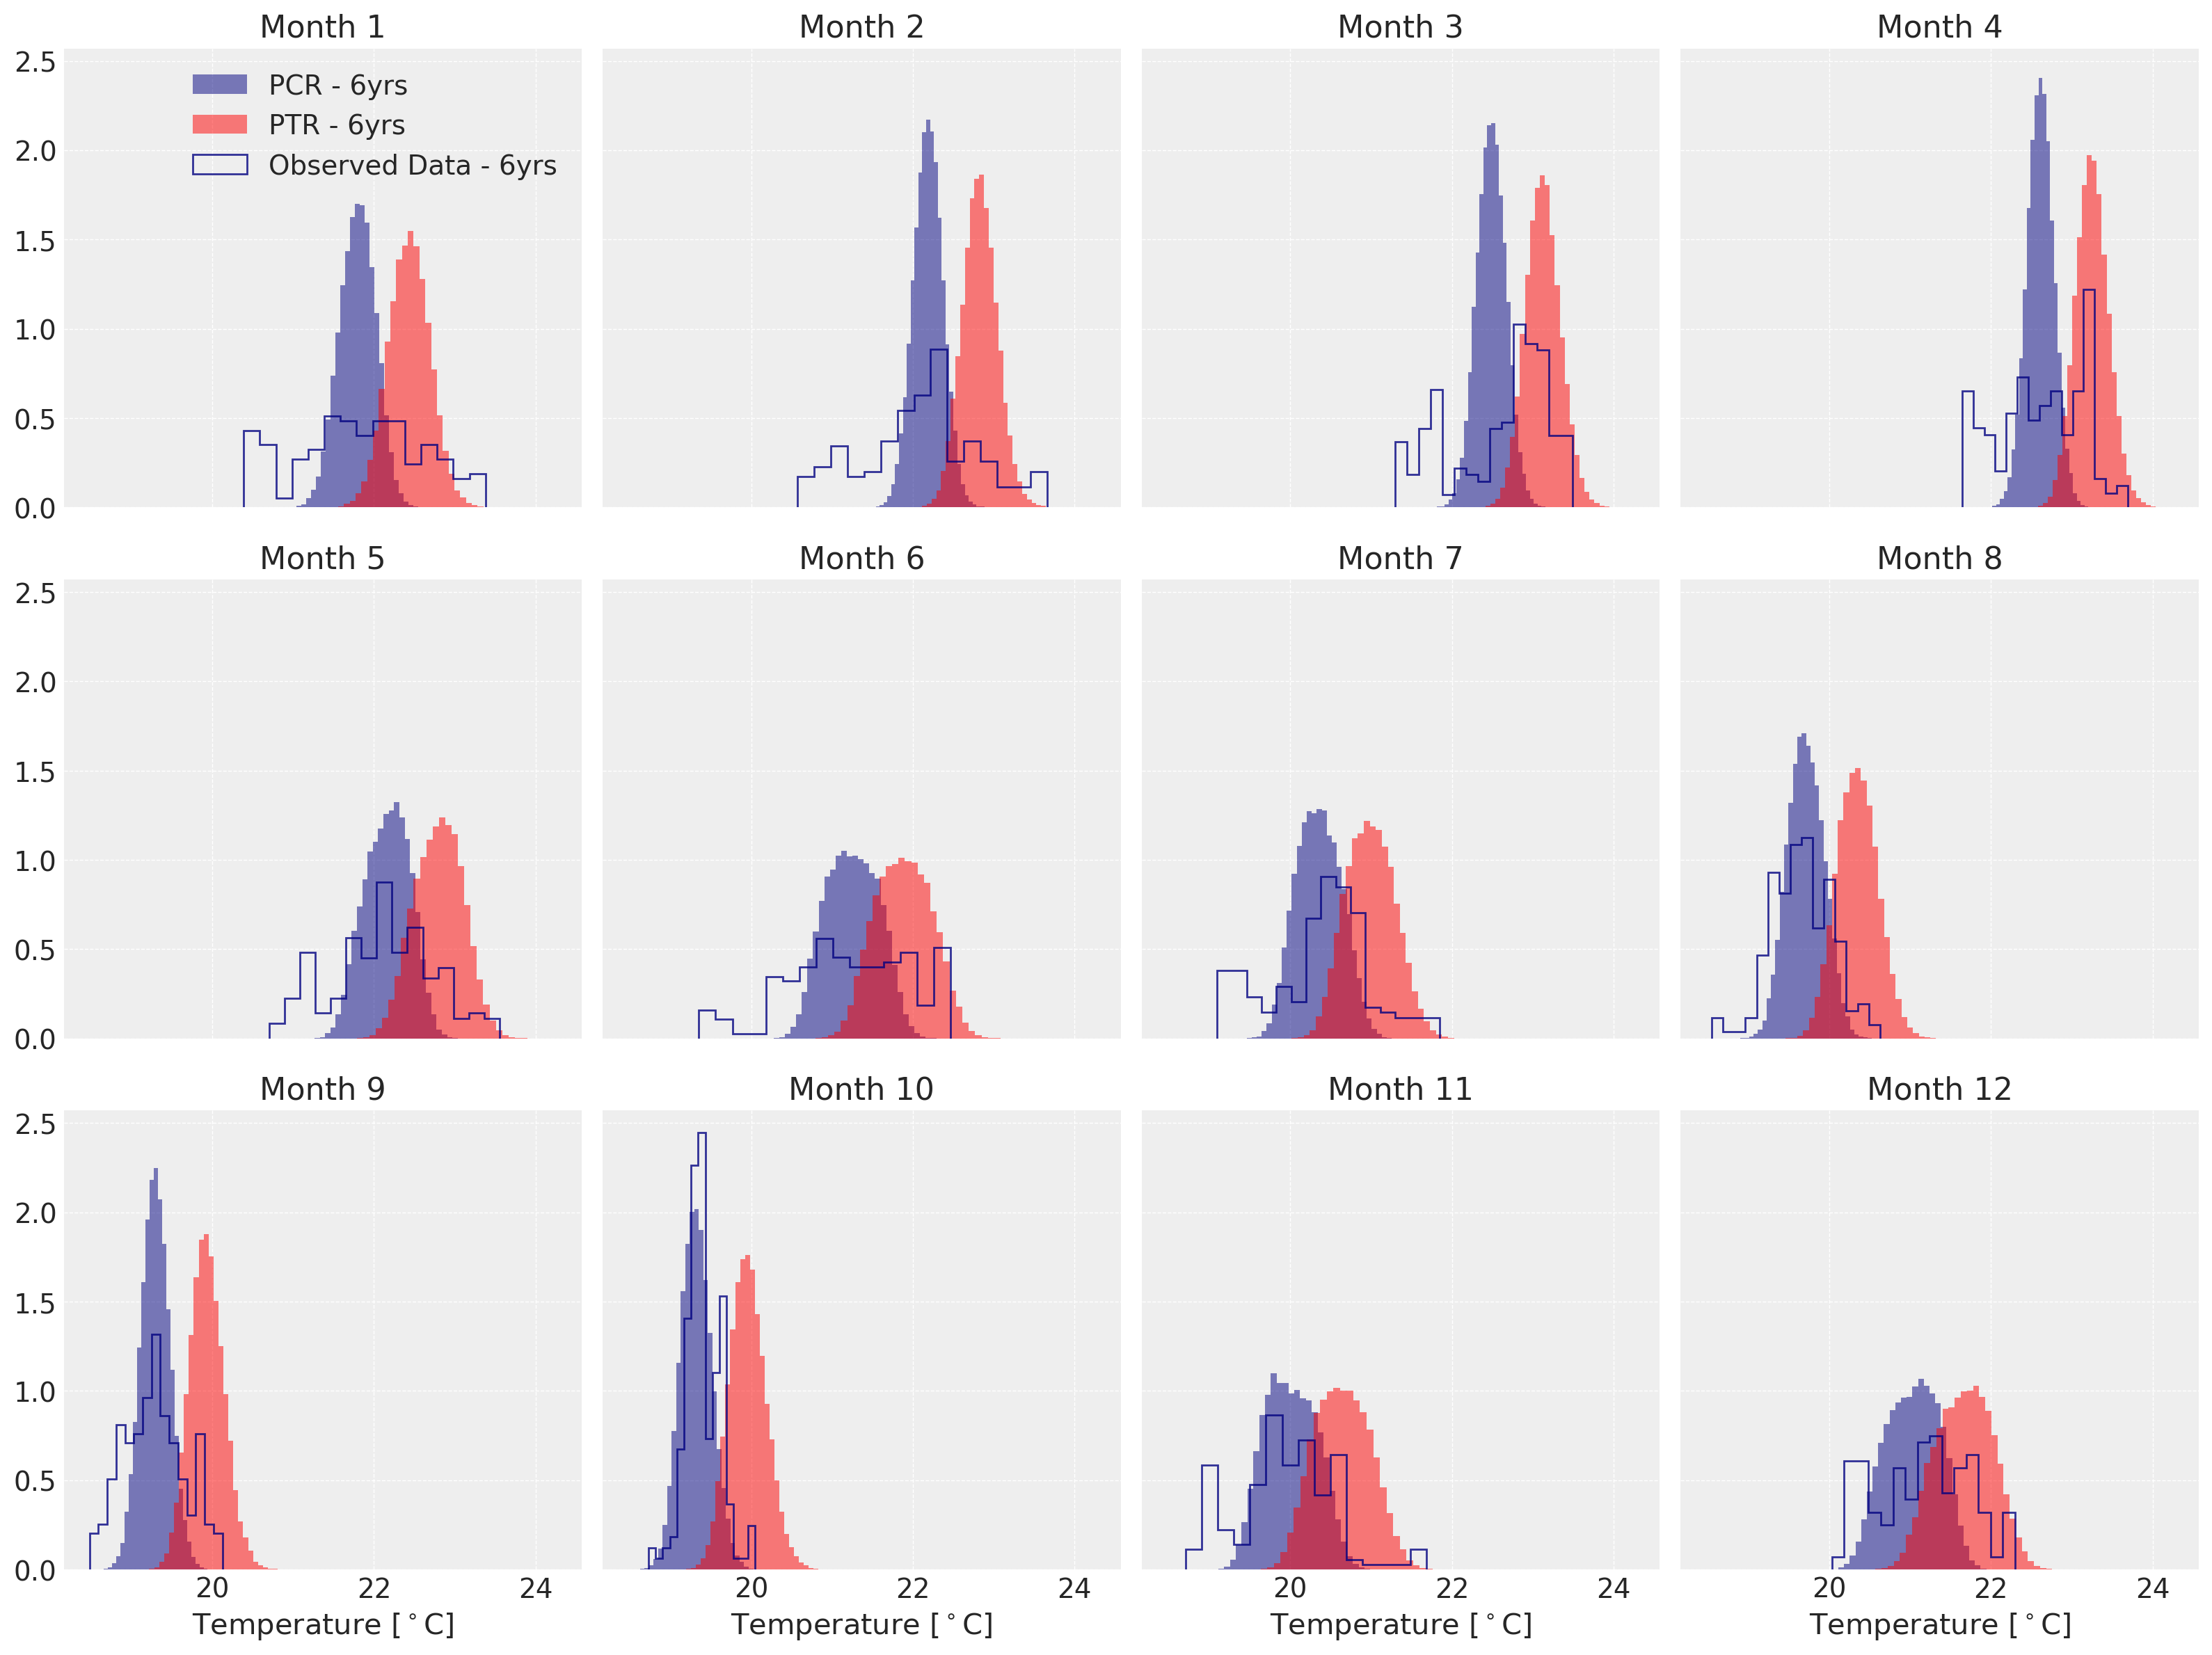

In [16]:
# ------------------------------------------------------------------------------
# Setup
# ------------------------------------------------------------------------------

# Posterior Climate Reference (PCR), Posterior Threshold Reference (PTR), and time axis
PCR, PTR, time_array = get_PCRs_and_PTR(idata_eps, df_C_roll)

# Extract month numbers from index (1–12)
months = pd.to_datetime(df_C_roll.index).month

# Create 3x4 subplot grid (one panel per month)
fig, axs = plt.subplots(3, 4, figsize=(16, 12), dpi=200, sharex=True, sharey=True)
axs = axs.flatten()

# ------------------------------------------------------------------------------
# Loop through each month (1–12)
# ------------------------------------------------------------------------------

for m in range(1, 13):
    ax = axs[m - 1]

    # Boolean mask for current month
    obs_id_mask = months == m

    # Observed data for this month
    obs_data = (idata_eps.observed_data.sel(obs_id=obs_id_mask).to_array().values.flatten())

    # Posterior predictive samples for this month
    pcr_month = PCR[:, obs_id_mask].flatten()  # PCR samples
    ptr_month = PTR[:, obs_id_mask].flatten()  # PTR samples

    # --------------------------------------------------------------------------
    # Plot histograms
    # --------------------------------------------------------------------------

    # PCR distribution
    ax.hist( pcr_month, bins=30, density=True,color="navy", alpha=0.5, histtype="stepfilled", label=f"PCR - {label_years}" )

    # PTR distribution
    ax.hist(ptr_month, bins=30, density=True, color="red", alpha=0.5, histtype="stepfilled", label=f"PTR - {label_years}")

    # Observed data distribution
    ax.hist(obs_data, bins=15, density=True,color="navy", alpha=0.8, histtype="step",label=f"Observed Data - {label_years}")

    # --------------------------------------------------------------------------
    # Formatting per subplot
    # --------------------------------------------------------------------------

    # Add x-axis labels only for bottom row
    if m >= 9:
        ax.set_xlabel("Temperature [$^\\circ$C]")

    # Add legend only in first subplot
    if m == 1:
        ax.legend()

    # Panel title
    ax.set_title(f"Month {m}")

# ------------------------------------------------------------------------------
# Final adjustments & save
# ------------------------------------------------------------------------------

plt.tight_layout()

# Save high-resolution PNG and PDF
plt.savefig(f"{figures_folder}/Likelihood_PTR_PCR_posterior_per_month_eps_{label_years}.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{figures_folder}/Likelihood_PTR_PCR_posterior_per_month_eps_{label_years}.pdf",dpi=300, bbox_inches="tight")

plt.show()